# 09 — Error analysis: what the model gets wrong, where, and how much it costs the alert

A macro F1 number is not an analysis. This notebook answers the questions the viva asks: which species are
confused with which, does the model fail more at night or at unseen camera sites, how confident is it when
it is wrong, and which specific errors produce missed alerts versus false alerts.

Predictor used: the notebook 07 checkpoint when it exists, otherwise the cached frozen-feature bank plus
the saved head — the code prints which, since the two are different models and the numbers are not
transferable between them.

In [1]:
import json, os, sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from torch.utils.data import DataLoader
from torchvision import transforms as T

ROOT = next(a for a in [Path.cwd(), *Path.cwd().parents] if (a / "data/splits").exists())
sys.path.insert(0, str(ROOT / "src/vision"))
sys.path.insert(0, str(ROOT / "src/sequence"))
import alert as A
import wildlife as W

IMG = ROOT / "data/raw/iwildcam_v2.0/train"
SP = ROOT / "data/splits"
BANK = ROOT / "data/processed/feature_bank.npz"
HEAD = ROOT / "outputs/checkpoints/species_head.joblib"
CKPT = ROOT / "outputs/checkpoints/finetune_reg.pt"
OUT = Path(os.environ.get("P11_OUT", ROOT / "outputs/logs/notebook09"))
OUT.mkdir(parents=True, exist_ok=True)
W.set_seed(W.SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() and torch.cuda.device_count() else "cpu")

class_map = pd.read_csv(SP / "class_map.csv").set_index("label")["class_name"]
N = len(class_map)
species_of = {i: str(class_map[i]) for i in range(N)}
test = W.on_disk(pd.read_csv(SP / "test.csv"), IMG)
print("test images:", len(test), "| sites:", test.location.nunique(),
      "| camera-days:", len(test.groupby(["location", test.datetime.astype(str).str[:10]])),
      "| device:", DEVICE, "| predictor:", "finetuned checkpoint" if CKPT.is_file() else "bank + head")

19928/19928 manifest images present in C:\Users\xxshi\Desktop\PYTHOM\DL_PBL\data\raw\iwildcam_v2.0\train
test images: 19928 | sites: 44 | camera-days: 633 | device: cuda | predictor: finetuned checkpoint


In [2]:
if CKPT.is_file():
    model = W.load_resnet50(None, n_classes=N, pretrained=False)
    model.load_state_dict(torch.load(CKPT, map_location="cpu"))
    tf = T.Compose([T.Resize((224, 224)), T.ToTensor(),
                    T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])
    model = model.to(DEVICE).eval()
    probs, ys = [], []
    with torch.no_grad():
        # shuffle=False keeps batch order, so the concatenated arrays still line up with the manifest
        for x, yy in DataLoader(W.WildlifeImages(test, IMG, tf), batch_size=256, num_workers=4):
            probs.append(torch.softmax(model(x.to(DEVICE)), 1).cpu().numpy())
            ys.append(yy.numpy())
    P, y = np.concatenate(probs), np.concatenate(ys)
    source = "finetuned_checkpoint"
else:
    z = np.load(BANK)
    bundle = joblib.load(HEAD)
    P = bundle["pipeline"].predict_proba(bundle["scaler"].transform(z["test_x"].astype(np.float32)))
    y = z["test_y"]
    source = "bank_frozen_features_logreg"
print("predictions:", P.shape, "| source:", source, "| accuracy:", round(float((P.argmax(1) == y).mean()), 4))
pred = P.argmax(1)
conf = P.max(1)
runner_up = np.sort(P, 1)[:, -2]
margin = conf - runner_up

predictions: (19928, 13) | source: finetuned_checkpoint | accuracy: 0.7762


## 1. Per-class accuracy: who is being missed

Support and recall side by side, because a rare class can look fine on average and still be invisible.

In [3]:
rows = []
for l in range(N):
    m = y == l
    rows.append({"class": species_of[l], "tier": A.DANGER_TIER.get(species_of[l], A.DEFAULT_TIER),
                 "test_images": int(m.sum()), "recall": round(float((pred[m] == l).mean()) if m.sum() else 0.0, 4),
                 "missed_as_empty": int((pred[m] == 0).sum()) if m.sum() else 0,
                 "mean_conf_when_wrong": round(float(conf[m & (pred != l)].mean()) if (m & (pred != l)).any() else float("nan"), 3)})
per_class = pd.DataFrame(rows).sort_values("recall")
per_class.to_csv(OUT / "per_class_errors.csv", index=False)
per_class.to_string(index=False)


'                   class  tier  test_images  recall  missed_as_empty  mean_conf_when_wrong\nurocyon cinereoargenteus     2          990  0.3182                8                 0.435\n          tayassu pecari     2            2  0.5000                1                 0.931\n           mazama temama     1          200  0.6300                0                 0.589\n           puma concolor     3          776  0.6314                3                 0.484\n     dasyprocta punctata     1         1087  0.6412                0                 0.478\n           panthera onca     4         1240  0.6653                9                 0.486\n      leopardus pardalis     3         1126  0.6661                0                 0.434\n      meleagris ocellata     1         2998  0.7141                9                 0.428\n              crax rubra     1         2116  0.7193                0                 0.488\n  cephalophus nigrifrons     1         1420  0.8099               86           

## 2. Confusion pairs

Aggregating the matrix into ordered pairs makes the biology visible: the errors that matter are big-cat
against big-cat and animal-against-empty, because those are exactly the alert decisions.

4459 errors of 19928 images (22.4%)


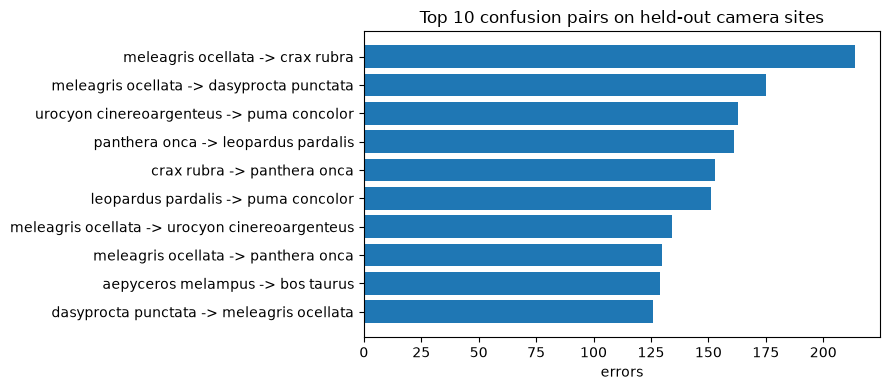

In [4]:
err = pred != y
pairs = (pd.DataFrame({"true": pd.Series(y[err]).map(species_of), "pred": pd.Series(pred[err]).map(species_of)})
         .groupby(["true", "pred"], observed=True).size().reset_index(name="count")
         .sort_values("count", ascending=False))
pairs["alert_relevant"] = np.where(
    pairs["true"].map(lambda s: A.DANGER_TIER.get(s, 0) >= 3) |
    pairs["pred"].map(lambda s: A.DANGER_TIER.get(s, 0) >= 3), "yes", "no")
print(f"{err.sum()} errors of {len(y)} images ({err.mean():.1%})")
pairs.head(15).to_string(index=False)
pairs.to_csv(OUT / "confusion_pairs.csv", index=False)
fig, ax = plt.subplots(figsize=(9, 4))
top = pairs.head(10)
ax.barh([f"{r['true']} -> {r['pred']}" for _, r in top.iterrows()][::-1], top["count"][::-1])
ax.set_xlabel("errors"); ax.set_title("Top 10 confusion pairs on held-out camera sites")
plt.tight_layout(); plt.savefig(OUT / "confusion_pairs.png", dpi=120)


## 3. Where errors cluster: site, night, and burst position

Errors are not independent. A camera site with a bad angle or a species it rarely sees can dominate the
whole test score, which is why per-site spread is reported next to the average.

day (00-17) accuracy 0.7865 | night (18-23) accuracy 0.6957
worst 5 sites: {231: 0.0, 282: 0.008, 502: 0.363, 499: 0.427, 519: 0.566}
site accuracy range: 0.0 to 1.0 | std 0.296


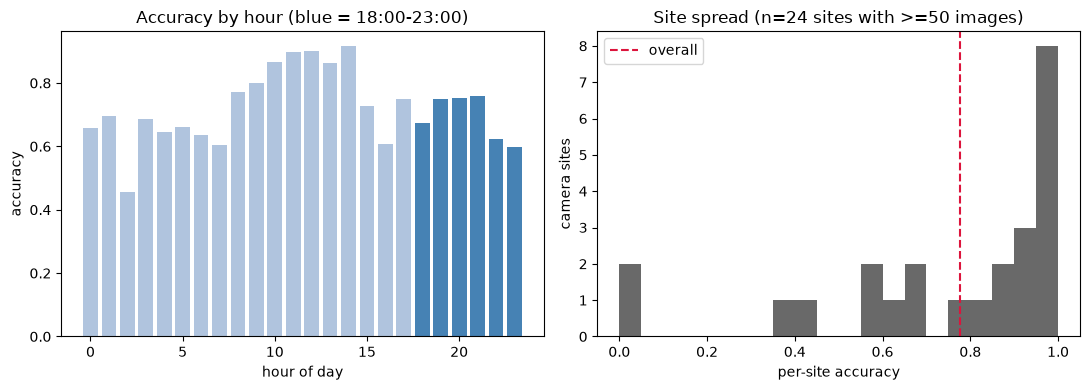

In [5]:
t = test.iloc[:len(pred)].copy()
t["pred"], t["conf"], t["margin"], t["error"] = pred, conf, margin, err
t["hour"] = pd.to_datetime(t.datetime).dt.hour
t["night"] = t.hour >= 18
t["correct"] = ~err
by_hour = t.groupby("hour").agg(n=("correct", "size"), acc=("correct", "mean"))
by_hour["night"] = by_hour.index >= 18
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar(by_hour.index, by_hour.acc, color=np.where(by_hour.night, "steelblue", "lightsteelblue"))
ax[0].set_xlabel("hour of day"); ax[0].set_ylabel("accuracy"); ax[0].set_title("Accuracy by hour (blue = 18:00-23:00)")
site = t.groupby("location").agg(n=("correct", "size"), acc=("correct", "mean")).query("n >= 50")
ax[1].hist(site.acc, bins=20, color="dimgray")
ax[1].axvline(t.correct.mean(), color="crimson", ls="--", label="overall")
ax[1].set_xlabel("per-site accuracy"); ax[1].set_ylabel("camera sites")
ax[1].set_title(f"Site spread (n={len(site)} sites with >=50 images)"); ax[1].legend()
plt.tight_layout(); plt.savefig(OUT / "error_clusters.png", dpi=120)
print("day (00-17) accuracy", round(float(t[~t.night].correct.mean()), 4),
      "| night (18-23) accuracy", round(float(t[t.night].correct.mean()), 4))
print("worst 5 sites:", site.nsmallest(5, "acc").round(3).to_dict()["acc"])
print("site accuracy range:", round(float(site.acc.min()), 3), "to", round(float(site.acc.max()), 3),
      "| std", round(float(site.acc.std()), 3))

## 4. Confidence when wrong, and calibration

A confident wrong answer is what makes a false alert. If confidence is well calibrated, a threshold can
filter it; if the model is confidently wrong in bursts, no threshold saves it — and that is the measured
finding behind the gate's residual false alerts.

                   n  predicted    actual     gap
conf                                             
(-0.001, 0.2]     93   0.182341  0.204301  0.0220
(0.2, 0.4]      2650   0.316155  0.267925 -0.0482
(0.4, 0.6]      3074   0.498101  0.518217  0.0201
(0.6, 0.8]      3969   0.716023  0.816830  0.1008
(0.8, 1.0]     10142   0.883502  0.976632  0.0931
expected calibration error: 0.0771
mean margin on errors: 0.273 | on correct: 0.7237


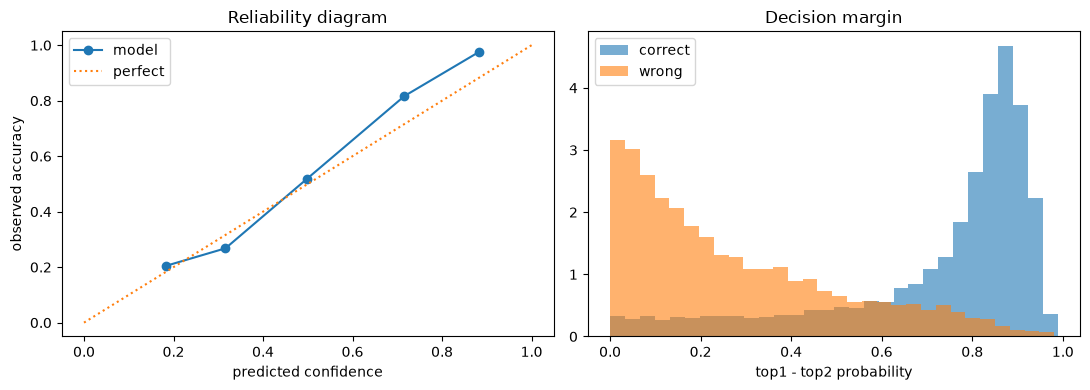

In [6]:
def ece(conf, correct, bins=10):
    idx = np.clip((conf * bins).astype(int), 0, bins - 1)
    out = 0.0
    for b in range(bins):
        m = idx == b
        if m.sum():
            out += m.mean() * abs(correct[m].mean() - conf[m].mean())
    return float(out)

bins = pd.cut(t.conf, np.linspace(0, 1, 6), include_lowest=True)
rel = t.groupby(bins, observed=True).agg(n=("correct", "size"), predicted=("conf", "mean"),
                                         actual=("correct", "mean"))
rel["gap"] = (rel.actual - rel.predicted).round(4)
print(rel.to_string())
print("expected calibration error:", round(ece(t.conf.to_numpy(), t.correct.to_numpy()), 4))
print("mean margin on errors:", round(float(t.margin[t.error].mean()), 4),
      "| on correct:", round(float(t.margin[~t.error].mean()), 4))
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(rel.predicted, rel.actual, "o-", label="model")
ax[0].plot([0, 1], [0, 1], ":", label="perfect")
ax[0].set_xlabel("predicted confidence"); ax[0].set_ylabel("observed accuracy"); ax[0].legend()
ax[0].set_title("Reliability diagram")
ax[1].hist(t.margin[~t.error], bins=30, alpha=0.6, label="correct", density=True)
ax[1].hist(t.margin[t.error], bins=30, alpha=0.6, label="wrong", density=True)
ax[1].set_xlabel("top1 - top2 probability"); ax[1].legend(); ax[1].set_title("Decision margin")
plt.tight_layout(); plt.savefig(OUT / "calibration.png", dpi=120)
rel.to_csv(OUT / "reliability.csv")

## 5. Cost to the alert stream

The same predictions feed the alert rule, so each model error becomes either a missed alert or a false
alert. This is the bridge between the classifier result and the product claim, and it is where the
residual false alerts in notebook 04 come from.

In [7]:
tbl = test.iloc[:len(pred)].copy()
evidence = A.visits_from_manifest(tbl, confidence=conf, predicted=pred)
truth = A.visits_from_manifest(tbl)
# visits_from_manifest returns location/seq_id/frames/label_used/conf only; the tier and species the
# merge below reads belong to the visit stream, so derive them here rather than assuming the module
# exports the forecast module columns.
for _v in (evidence, truth):
    _v["species"] = _v["label_used"].map(species_of)
    _v["tier"] = _v["species"].map(lambda s: A.DANGER_TIER.get(s, A.DEFAULT_TIER))
cfg = A.AlertConfig()
res = A.evaluate_per_frame_vs_gated(evidence, truth, species_of, cfg)
print(json.dumps(res, indent=2))

# Which species the model's mistakes turn into alerts, and which real incidents it drops.
fp = evidence.merge(truth[["location", "seq_id", "tier", "species"]], on=["location", "seq_id"],
                   suffixes=("_pred", "_true"))
bad = fp[(fp.tier_pred >= cfg.tier_min) & (fp.tier_true < cfg.tier_min)]
missed = fp[(fp.tier_true >= cfg.tier_min) & (fp.tier_pred < cfg.tier_min)]
print("visits alerted that really were not dangerous:", len(bad))
print(bad.species_pred.value_counts().to_frame("predicted").join(
    bad.species_true.value_counts().rename("truth").to_frame(), how="left").fillna(0).astype(int).to_string())
print("dangerous visits the model did not flag:", len(missed))
print(missed.groupby(["species_true", "species_pred"]).size().sort_values(ascending=False).head(8).to_string())
bad.to_csv(OUT / "alert_false_visits.csv", index=False)
missed.to_csv(OUT / "alert_missed_visits.csv", index=False)


{
  "camera_days": 633,
  "qualifying_camera_days": 139,
  "days_with_no_animal": 191,
  "gated": {
    "alerts": 80,
    "alerts_per_camera_day": 0.1264,
    "true_alerts": 66,
    "false_alerts": 14,
    "missed_alerts": 73,
    "precision": 0.825,
    "recall_of_qualifying_days": 0.4748
  },
  "per_frame": {
    "alerts": 192,
    "alerts_per_camera_day": 0.3033,
    "true_alerts": 126,
    "false_alerts": 66,
    "missed_alerts": 13,
    "precision": 0.6562,
    "recall_of_qualifying_days": 0.9065
  },
  "alerts_reduced_by": 0.5833
}
visits alerted that really were not dangerous: 146
                    predicted  truth
species_pred                        
panthera onca              74      0
puma concolor              56      0
leopardus pardalis         16      0
dangerous visits the model did not flag: 55
species_true        species_pred            
leopardus pardalis  urocyon cinereoargenteus    13
panthera onca       dasyprocta punctata          5
                    empty    

saved C:\Users\xxshi\Desktop\PYTHOM\DL_PBL\outputs\logs\notebook09\error_examples.png


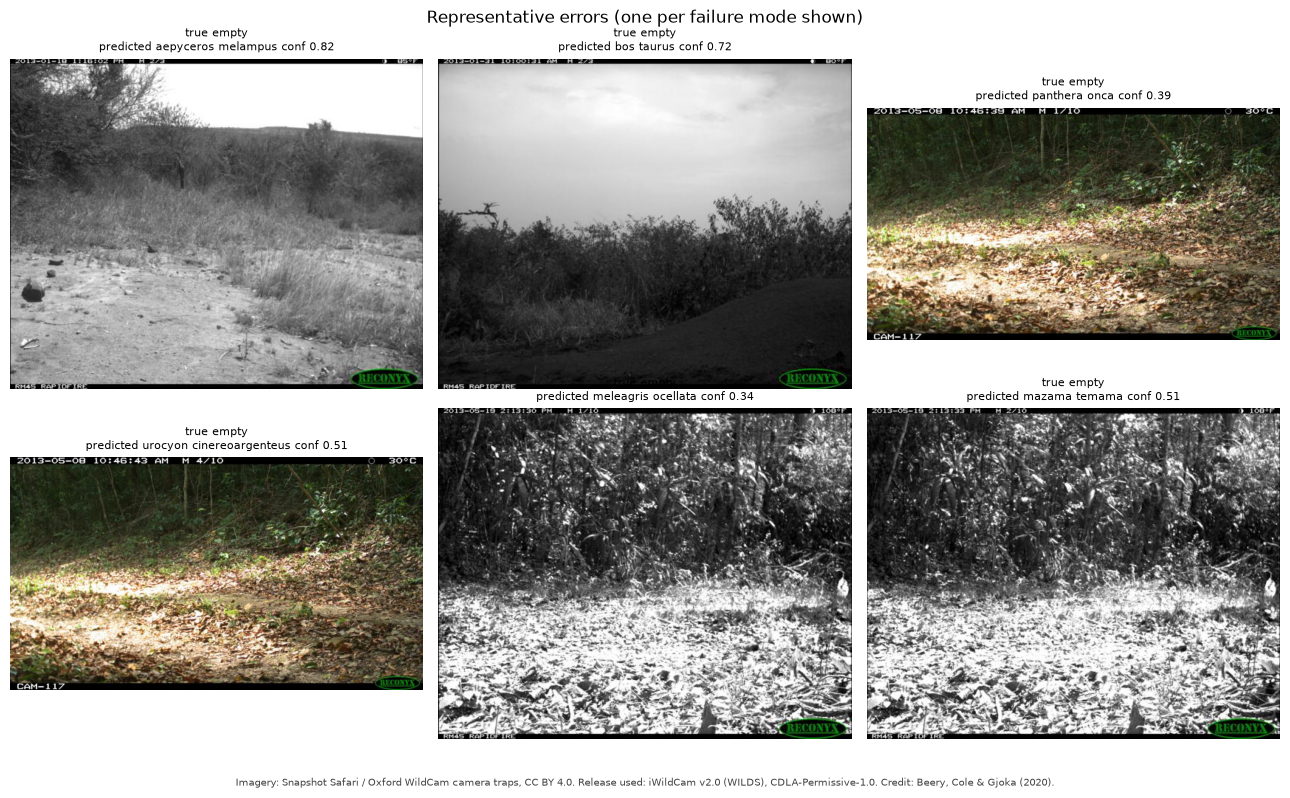

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
show = pd.concat([t[t.error].groupby(t[t.error].pred).head(1),
                  t[(t.pred == 0) & (t.label != 0)].head(2)])
for ax, (_, r) in zip(axes.ravel(), show.iterrows()):
    with Image.open(IMG / r.filename) as im:
        ax.imshow(np.asarray(im.convert("RGB")))
    ax.set_title(f"true {species_of[int(r.label)]}\npredicted {species_of[int(r.pred)]} "
                 f"conf {r.conf:.2f}", fontsize=8)
    ax.axis("off")
for ax in axes.ravel()[len(show):]:
    ax.axis("off")
plt.suptitle("Representative errors (one per failure mode shown)")
fig.text(0.5, 0.01, "Imagery: Snapshot Safari / Oxford WildCam camera traps, CC BY 4.0. Release used: "
                    "iWildCam v2.0 (WILDS), CDLA-Permissive-1.0. Credit: Beery, Cole & Gjoka (2020).",
         ha="center", fontsize=7, color="#444444")
plt.tight_layout(rect=(0, 0.04, 1, 1)); plt.savefig(OUT / "error_examples.png", dpi=120)
print("saved", OUT / "error_examples.png")

## 6. What this changes for the next step

Read the outputs before writing conclusions. The decisions this analysis is designed to inform: whether a
confidence threshold on the margin distribution is worth adding to the alert rule, whether the residual
false alerts are a classifier problem (confident multi-visit confusion) or a rule problem, and which
species need more training data before the conflict claim can be made for them at all.